In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
import os

In [2]:
# Thay đổi đường dẫn này thành thư mục data cục bộ trên máy tính của bạn
file_path = "../data/vietnam_housing_dataset.csv"

house_data = pd.read_csv(file_path)
house_data.head()

FileNotFoundError: [Errno 2] No such file or directory: '../data/vietnam_housing_dataset.csv'

In [3]:
import os
import shutil
import kagglehub

# 1. Tải dataset từ Kaggle về thư mục lưu cache mặc định của kagglehub
print("Đang tải dữ liệu từ Kaggle...")
path = kagglehub.dataset_download("nguyentiennhan/vietnam-housing-dataset-2024")

print("Đã tải về tại đường dẫn tạm:", path)

# 2. Tạo sẵn thư mục data/ nếu chưa có
os.makedirs("../data", exist_ok=True)

# 3. Tìm file csv trong thư mục vừa tải và copy vào thư mục data/ của dự án
for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            src_file = os.path.join(root, file)
            dst_file = "../data/vietnam_housing_dataset.csv"
            shutil.copy(src_file, dst_file)
            print(f"Đã copy file thành công vào: {dst_file}")

Đang tải dữ liệu từ Kaggle...


100%|██████████| 654k/654k [00:01<00:00, 617kB/s]

Extracting files...
Đã tải về tại đường dẫn tạm: C:\Users\caoth\.cache\kagglehub\datasets\nguyentiennhan\vietnam-housing-dataset-2024\versions\8
Đã copy file thành công vào: ../data/vietnam_housing_dataset.csv


In [1]:
#đọc dữ liệu và xem kích thước của tập dự liệu 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc file dữ liệu từ thư mục data cục bộ
file_path = "../data/vietnam_housing_dataset.csv"
house_data = pd.read_csv(file_path)

# Xem kích thước và 5 dòng đầu tiên
print(f"Kích thước bộ dữ liệu: {house_data.shape[0]} dòng, {house_data.shape[1]} cột")
display(house_data.head())

Kích thước bộ dữ liệu: 30229 dòng, 12 cột


,Address,Area,Frontage,Access Road,House direction,Balcony direction,Floors,Bedrooms,Bathrooms,Legal status,Furniture state,Price
0,"Dự án The Empire - Vinhomes Ocean Park 2, Xã L...",84.0,NaN,NaN,NaN,NaN,4.0,NaN,NaN,Have certificate,NaN,8.60
1,"Dự án The Crown - Vinhomes Ocean Park 3, Xã Ng...",60.0,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN,7.50
2,"Dự án The Crown - Vinhomes Ocean Park 3, Xã Ng...",90.0,6.0,13.0,Đông - Bắc,Đông - Bắc,5.0,NaN,NaN,Sale contract,NaN,8.90
3,"Đường Nguyễn Văn Khối, Phường 11, Gò Vấp, Hồ C...",54.0,NaN,3.5,Tây - Nam,Tây - Nam,2.0,2.0,3.0,Have certificate,Full,5.35
4,"Đường Quang Trung, Phường 8, Gò Vấp, Hồ Chí Minh",92.0,NaN,NaN,Đông - Nam,Đông - Nam,2.0,4.0,4.0,Have certificate,Full,6.90


In [3]:
# Số tầng, phòng ngủ, phòng vệ sinh thiếu $\rightarrow$ Gán mặc định là 1.   Mặt tiền, đường vào thiếu Gán là 0 (tính như không có thông tin).   Trạng thái pháp lý và nội thất thiếu Điền là 'None'.   
# Điền giá trị khuyết cho các cột số
# Điền giá trị khuyết cho các cột số bằng cú pháp mới
house_data['Floors'] = house_data['Floors'].fillna(1)
house_data['Bedrooms'] = house_data['Bedrooms'].fillna(1)
house_data['Bathrooms'] = house_data['Bathrooms'].fillna(1)
house_data['Frontage'] = house_data['Frontage'].fillna(0)
house_data['Access Road'] = house_data['Access Road'].fillna(0)

# Điền giá trị khuyết cho các cột chữ
house_data['Legal status'] = house_data['Legal status'].fillna('None')
house_data['Furniture state'] = house_data['Furniture state'].fillna('None')

print("Đã xử lý xong giá trị khuyết mà không còn cảnh báo!")

Đã xử lý xong giá trị khuyết mà không còn cảnh báo!


In [4]:
# Tách lấy Tỉnh/Thành phố
house_data['Province'] = house_data['Address'].str.split(", ").str[-1].str.replace(".", "")

# Tạo cờ đánh dấu có thuộc dự án hay không (1: Có, 0: Không)
house_data['Project'] = house_data['Address'].str.lower().str.contains('dự án').map({True: 1, False: 0})

# Bỏ cột Address thô vì đã trích xuất xong thông tin
house_data.drop('Address', axis=1, inplace=True)

# Lọc bỏ các tỉnh có quá ít mẫu (dưới 5 mẫu) để tránh nhiễu
unique_provinces = house_data['Province'].value_counts()
rare_provinces = unique_provinces[unique_provinces < 5].index
house_data = house_data[~house_data['Province'].isin(rare_provinces)]

print("Đã hoàn thành trích xuất đặc trưng địa điểm!")

Đã hoàn thành trích xuất đặc trưng địa điểm!


In [5]:
from sklearn.model_selection import train_test_split

# Tách biến độc lập (X) và biến mục tiêu cần dự đoán (y: Giá nhà)
X = house_data.copy()
y = X.pop('Price')

# Chuyển đổi toàn bộ các cột chữ còn lại thành dạng số dạng cột giả (dummy variables)
X = pd.get_dummies(X)

# Chia tập dữ liệu Train / Test (80% / 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Kích thước tập Train: {X_train.shape}")
print(f"Kích thước tập Test:  {X_test.shape}")

Kích thước tập Train: (24148, 77)
Kích thước tập Test:  (6038, 77)


In [6]:
from sklearn.linear_model import Ridge, Lasso
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

# 1. Huấn luyện mô hình Ridge Regression
ridge = Ridge(alpha=10)
ridge.fit(X_train, y_train)
ridge_pred = ridge.predict(X_test)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_pred))

# 2. Huấn luyện mô hình Lasso Regression
lasso = Lasso(alpha=0.01)
lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_pred))

# 3. Huấn luyện mô hình XGBoost Regressor (Mô hình mạnh nhất)
xgb_model = XGBRegressor(
    objective='reg:squarederror',
    random_state=42,
    learning_rate=0.01,
    max_depth=7,
    n_estimators=500
)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_mape = mean_absolute_percentage_error(y_test, xgb_pred)

# In kết quả so sánh
print("--- SO SÁNH KẾT QUẢ CÁC MÔ HÌNH HỒI QUY ---")
print(f"Ridge Regression RMSE : {ridge_rmse:.2f}")
print(f"Lasso Regression RMSE : {lasso_rmse:.2f}")
print(f"XGBoost Regressor RMSE: {xgb_rmse:.2f}")
print(f"XGBoost Regressor MAPE: {xgb_mape * 100:.2f}%")

--- SO SÁNH KẾT QUẢ CÁC MÔ HÌNH HỒI QUY ---
Ridge Regression RMSE : 1.87
Lasso Regression RMSE : 1.89
XGBoost Regressor RMSE: 1.57
XGBoost Regressor MAPE: 27.20%


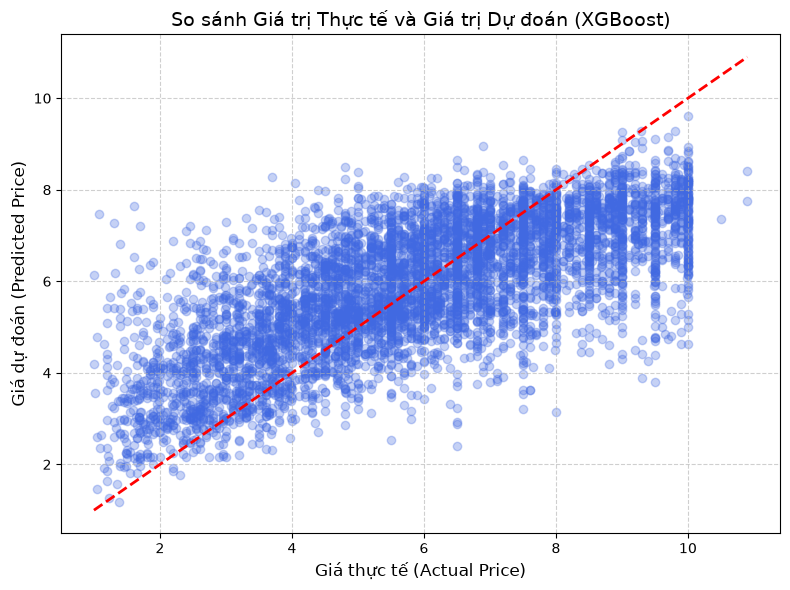

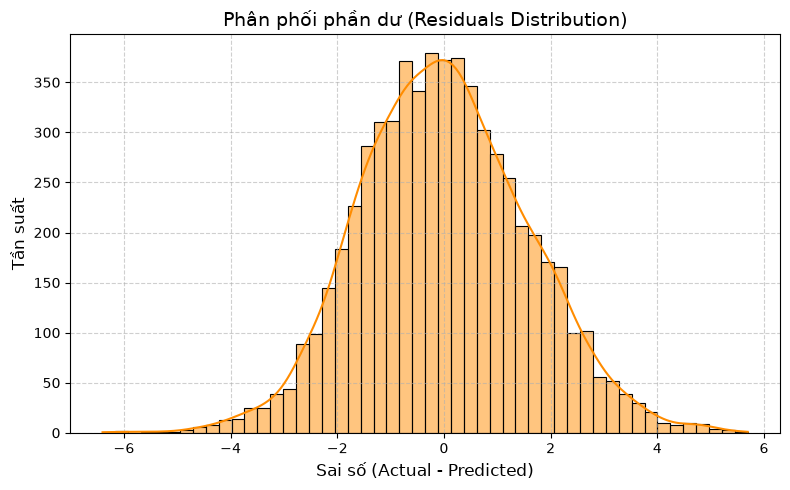

Đã vẽ và lưu thành công các biểu đồ vào thư mục 'images/'!


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Đảm bảo thư mục images đã tồn tại
os.makedirs("../images", exist_ok=True)

# 1. Biểu đồ Actual vs. Predicted (Thực tế vs Dự đoán)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, xgb_pred, alpha=0.3, color='royalblue')
# Vẽ đường chéo tham chiếu lý tưởng (y = x)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('So sánh Giá trị Thực tế và Giá trị Dự đoán (XGBoost)', fontsize=14)
plt.xlabel('Giá thực tế (Actual Price)', fontsize=12)
plt.ylabel('Giá dự đoán (Predicted Price)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("../images/actual_vs_predicted.png", dpi=300)
plt.show()

# 2. Biểu đồ phân phối phần dư (Residuals Distribution)
residuals = y_test - xgb_pred
plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True, bins=50, color='darkorange')
plt.title('Phân phối phần dư (Residuals Distribution)', fontsize=14)
plt.xlabel('Sai số (Actual - Predicted)', fontsize=12)
plt.ylabel('Tần suất', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("../images/residuals_distribution.png", dpi=300)
plt.show()

print("Đã vẽ và lưu thành công các biểu đồ vào thư mục 'images/'!")

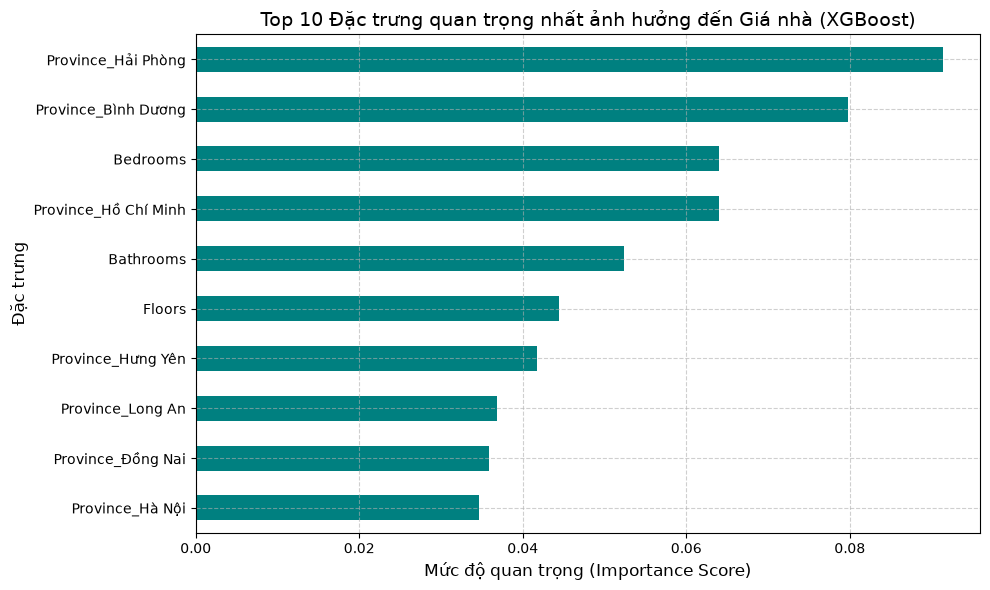

In [8]:
# Lấy độ quan trọng của các đặc trưng từ mô hình XGBoost
feature_importances = pd.Series(xgb_model.feature_importances_, index=X_train.columns)

# Sắp xếp và lấy ra Top 10 đặc trưng quan trọng nhất
plt.figure(figsize=(10, 6))
feature_importances.nlargest(10).plot(kind='barh', color='teal')
plt.title('Top 10 Đặc trưng quan trọng nhất ảnh hưởng đến Giá nhà (XGBoost)', fontsize=14)
plt.xlabel('Mức độ quan trọng (Importance Score)', fontsize=12)
plt.ylabel('Đặc trưng', fontsize=12)
plt.gca().invert_yaxis() # Đảo chiều để đặc trưng quan trọng nhất lên trên cùng
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("../images/feature_importance.png", dpi=300)
plt.show()

C:\Users\caoth\AppData\Local\Temp\ipykernel_18148\3548165758.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Province', y='Price', data=house_data, palette='Set2')


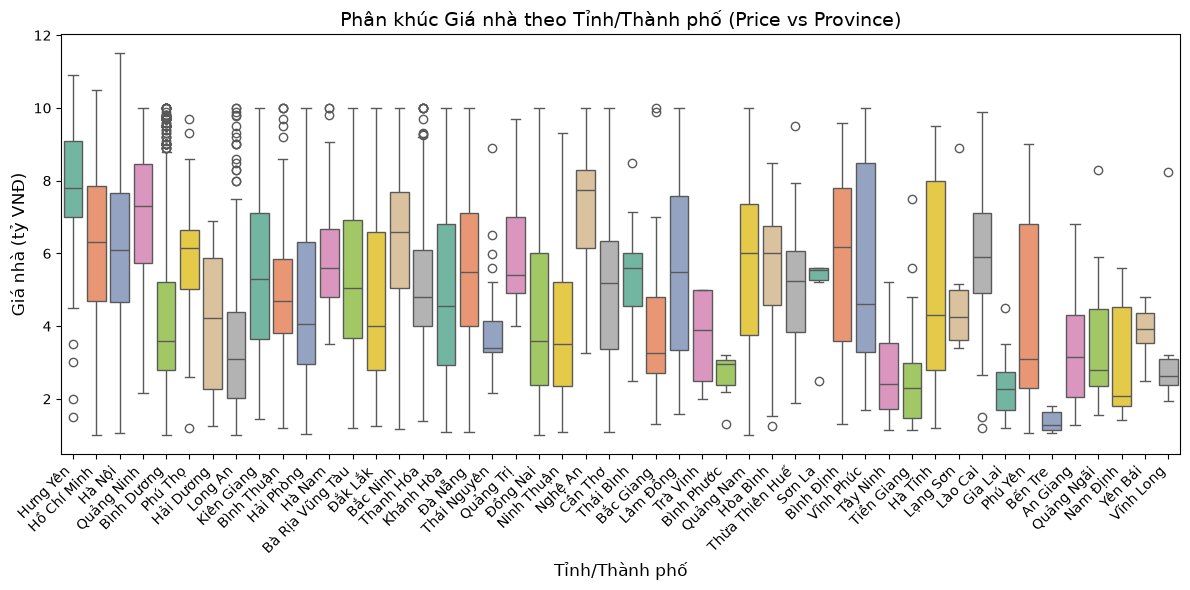

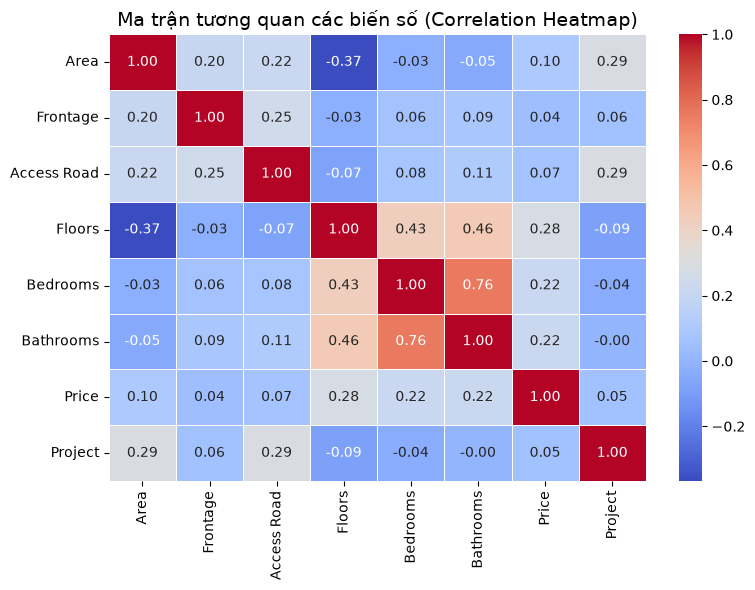

Đã vẽ và lưu thêm Boxplot và Heatmap vào thư mục 'images/' thành công!


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("../images", exist_ok=True)

# 1. Biểu đồ Boxplot: Giá nhà theo Tỉnh/Thành phố (Price vs Province)
if 'Province' in house_data.columns:
    plt.figure(figsize=(12, 6))
    sns.boxplot(x='Province', y='Price', data=house_data, palette='Set2')
    plt.title('Phân khúc Giá nhà theo Tỉnh/Thành phố (Price vs Province)', fontsize=14)
    plt.xlabel('Tỉnh/Thành phố', fontsize=12)
    plt.ylabel('Giá nhà (tỷ VNĐ)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig("../images/price_vs_province_boxplot.png", dpi=300)
    plt.show()

# 2. Biểu đồ Correlation Heatmap (Ma trận tương quan các biến số)
plt.figure(figsize=(8, 6))
numeric_cols = house_data.select_dtypes(include=[np.number]).columns
corr_matrix = house_data[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5, cbar=True)
plt.title('Ma trận tương quan các biến số (Correlation Heatmap)', fontsize=14)
plt.tight_layout()
plt.savefig("../images/correlation_heatmap.png", dpi=300)
plt.show()

print("Đã vẽ và lưu thêm Boxplot và Heatmap vào thư mục 'images/' thành công!")

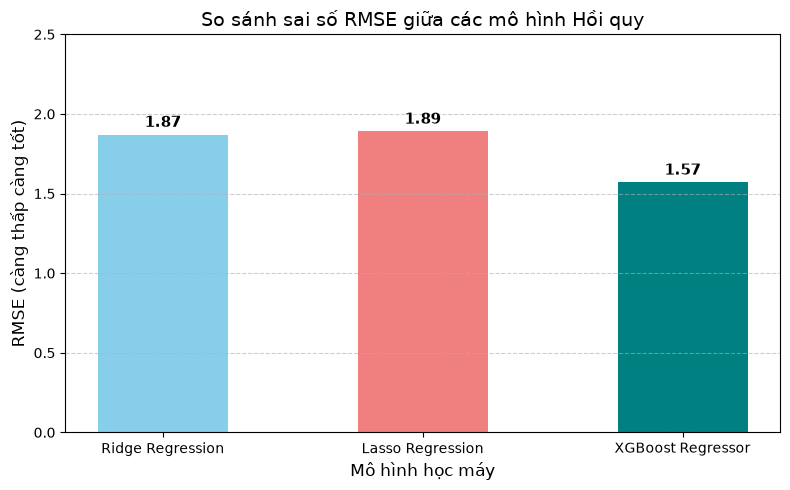

Đã vẽ và lưu biểu đồ so sánh mô hình thành `model_comparison_rmse.png` vào thư mục images/!


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Đảm bảo thư mục images đã tồn tại
os.makedirs("../images", exist_ok=True)

# Dữ liệu kết quả RMSE của các mô hình từ thực nghiệm của bạn
models = ['Ridge Regression', 'Lasso Regression', 'XGBoost Regressor']
rmse_values = [1.87, 1.89, 1.57]  # Lấy từ kết quả console của bạn

# Vẽ biểu đồ cột so sánh RMSE
plt.figure(figsize=(8, 5))
bars = plt.bar(models, rmse_values, color=['skyblue', 'lightcoral', 'teal'], width=0.5)

plt.title('So sánh sai số RMSE giữa các mô hình Hồi quy', fontsize=14)
plt.xlabel('Mô hình học máy', fontsize=12)
plt.ylabel('RMSE (càng thấp càng tốt)', fontsize=12)
plt.ylim(0, 2.5)
plt.grid(True, linestyle='--', alpha=0.6, axis='y')

# Gắn nhãn giá trị trực tiếp lên trên mỗi cột
for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.2f}',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3),  # 3 points vertical offset
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.tight_layout()
# Lưu biểu đồ vào thư mục images/
plt.savefig("../images/model_comparison_rmse.png", dpi=300)
plt.show()

print("Đã vẽ và lưu biểu đồ so sánh mô hình thành `model_comparison_rmse.png` vào thư mục images/!")